# Validate correlogram engines

This notebook validates the brute-force reference, FFT production, and optional PySAL Moran's I engines. All computation is provided by `change_ci`; notebook cells only configure examples, display results, and benchmark execution.

In [ ]:
import time
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from scipy.ndimage import gaussian_filter

from change_ci.discovery import PairSpec
from change_ci.engines import BruteForceEngine, FFTEngine, PySALEngine
from change_ci.estimation import estimate_effective_n
from change_ci.raster import RasterPair

ROOT = Path.cwd().parent
assert (ROOT / "pyproject.toml").exists(), "Run notebooks from the notebooks/ folder"

## 1. Worked brute-force example
A ring at lag 2 contains exactly the offsets whose Chebyshev distance is 2.

lags: [1 2 3]
Moran I: [0.75708 0.45855 0.10957]
ordered pair counts: [306 470 514]


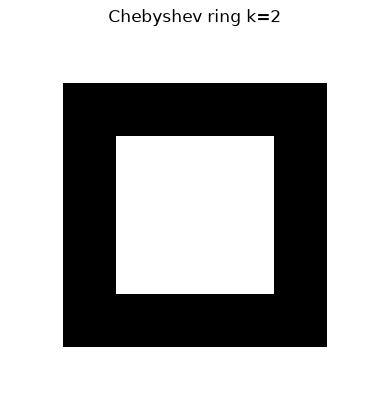

In [2]:
values = np.arange(49, dtype=float).reshape(7, 7)
values[0, 0] = np.nan
engine = BruteForceEngine()
data = engine.compute(values, max_lag=3)
print('lags:', data.lags)
print('Moran I:', np.round(data.moran_i, 5))
print('ordered pair counts:', data.pair_counts)

ring = np.zeros_like(values, dtype=float)
center = (3, 3)
for row in range(values.shape[0]):
    for col in range(values.shape[1]):
        ring[row, col] = max(abs(row - center[0]), abs(col - center[1]))
plt.imshow(ring == 2, cmap='Greys')
plt.title('Chebyshev ring k=2')
plt.axis('off')
plt.show()

For one lag, Eq. 6 divides the summed paired deviation products by the ordered pair count and the total deviation sum of squares.

In [3]:
valid = np.isfinite(values)
deviations = np.where(valid, values - np.nanmean(values), 0.0)
print('lag 1 ordered pairs:', data.pair_counts[0])
print('lag 1 Moran I:', data.moran_i[0])
print('deviation sum of squares:', np.square(deviations).sum())

lag 1 ordered pairs: 306
lag 1 Moran I: 0.7570772990047082
deviation sum of squares: 9212.0


## 2. Synthetic sanity checks
White noise should have weak autocorrelation; spatially smoothed noise should have a decaying correlogram and smaller effective sample size.

white-noise mean I, lags 1-20: 0.00087771582069293
white-noise n_eff: 10000.0 range: 1
smoothed first five I: [0.9685 0.9073 0.8206 0.7172 0.6066]
smoothed n_eff: 49.84785507300935 range: 15


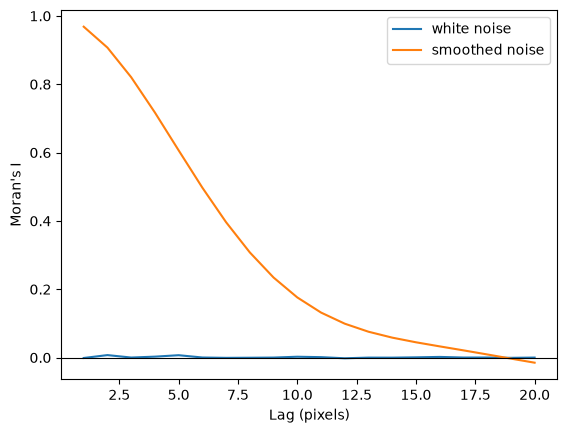

In [4]:
rng = np.random.default_rng(20260927)
noise = rng.normal(size=(100, 100))
smoothed = gaussian_filter(noise, sigma=4)
noise_data = FFTEngine().compute(noise, max_lag=20)
smooth_data = FFTEngine().compute(smoothed, max_lag=20)
noise_n_eff = estimate_effective_n(noise_data, noise.size, 0.05)
smooth_n_eff = estimate_effective_n(smooth_data, smoothed.size, 0.05)
print('white-noise mean I, lags 1-20:', float(np.nanmean(noise_data.moran_i)))
print('white-noise n_eff:', noise_n_eff.n_eff, 'range:', noise_n_eff.range_px)
print('smoothed first five I:', np.round(smooth_data.moran_i[:5], 4))
print('smoothed n_eff:', smooth_n_eff.n_eff, 'range:', smooth_n_eff.range_px)
plt.plot(noise_data.lags, noise_data.moran_i, label='white noise')
plt.plot(smooth_data.lags, smooth_data.moran_i, label='smoothed noise')
plt.axhline(0, color='black', linewidth=0.8)
plt.legend()
plt.xlabel('Lag (pixels)')
plt.ylabel("Moran's I")
plt.show()

## 3. Three-engine agreement

In [5]:
def compare_engines(values, max_lag=10):
    reference = BruteForceEngine().compute(values, max_lag)
    comparisons = {'fft': FFTEngine().compute(values, max_lag)}
    try:
        comparisons['pysal'] = PySALEngine(max_pixels=40_000).compute(values, max_lag)
    except ImportError:
        print('PySAL unavailable; optional comparison skipped.')
    for name, result in comparisons.items():
        print(name, 'max abs I difference:', np.nanmax(np.abs(result.moran_i - reference.moran_i)),
              'pair counts equal:', np.array_equal(result.pair_counts, reference.pair_counts))

comparison_values = rng.normal(size=(100, 100))
compare_engines(comparison_values)
comparison_values[20:35, 40:60] = np.nan
compare_engines(comparison_values)

/home/tshihadah/code/wadi-gaza-research/.venv/lib/python3.12/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


fft max abs I difference: 5.204170427930421e-18 pair counts equal: True
pysal max abs I difference: 1.734723475976807e-18 pair counts equal: True
fft max abs I difference: 3.903127820947816e-18 pair counts equal: True
pysal max abs I difference: 1.734723475976807e-18 pair counts equal: True


## 4. Full-size real-pair comparison

In [6]:
root = ROOT / 'outputs' / 'composites' / 'WadiGaza'
spec = PairSpec('WadiGaza', '09', 2023, 2024, root / 'WadiGaza_2023-09.tif', root / 'WadiGaza_2024-09.tif')
pair = RasterPair(spec)
fft_data = FFTEngine().compute(pair.values, pair.k_max)
brute_data = BruteForceEngine().compute(pair.values, pair.k_max)
print('shape:', pair.values.shape, 'valid pixels:', pair.n, 'k_max:', pair.k_max)
print('maximum Moran I difference:', np.nanmax(np.abs(fft_data.moran_i - brute_data.moran_i)))
print('pair counts identical:', np.array_equal(fft_data.pair_counts, brute_data.pair_counts))

Raster pixels are not square: (10.000130544932714, 10.006954791496103)


shape: (457, 510) valid pixels: 29455 k_max: 114
maximum Moran I difference: 2.220446049250313e-16
pair counts identical: True


## 5. Benchmarks
The benchmark uses lags 1-10 to keep the reference engine practical at larger windows. The full-range comparison above tests all production lags.

In [ ]:
benchmark_rows = []
for size in (50, 100, 250, 500):
    sample = rng.normal(size=(size, size))
    for name, engine in [('bruteforce', BruteForceEngine()), ('fft', FFTEngine())]:
        start = time.perf_counter()
        engine.compute(sample, max_lag=15)
        benchmark_rows.append({'size': size, 'engine': name, 'seconds': time.perf_counter() - start})
    if size <= 100:
        try:
            start = time.perf_counter()
            PySALEngine(max_pixels=40_000).compute(sample, max_lag=15)
            benchmark_rows.append({'size': size, 'engine': 'pysal', 'seconds': time.perf_counter() - start})
        except ImportError:
            pass
benchmark = pd.DataFrame(benchmark_rows)
benchmark

,size,engine,seconds
0,50,bruteforce,0.010691
1,50,fft,0.007050
2,50,pysal,35.781824
3,100,bruteforce,0.021199
4,100,fft,0.010815
5,100,pysal,201.696329
6,250,bruteforce,0.127751
7,250,fft,0.071390
8,500,bruteforce,0.623914
9,500,fft,0.287326
